# COMP2000 Assessment 1 - Exercise 4: Effect of model width and depth

Six CNN variants (all other settings identical):
- **Width** (2 conv layers, channels doubled in 2nd layer): [16,32], [32,64], [64,128]
- **Depth** (all conv layers 32 channels; pooling after the first 3 only): 1, 3, 5 conv layers

In [2]:
import os, time, copy, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

EPOCHS = 30         
LR = 1e-3           
BATCH_SIZE = 128
NUM_WORKERS = 2      
ROOT = "./data"
os.makedirs("figures", exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if torch.backends.mps.is_available() else "cpu")
print("Using device:", DEVICE)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

Using device: cpu


In [ ]:
CLASSES = ["aeroplane","automobile","bird","cat","deer","dog","frog","horse","ship","truck"]
MEAN, STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616) 

eval_tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

aug_tf = transforms.Compose([
    transforms.RandomAffine(degrees=10, translate=(0.1, 0.1)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

train_eval_full = datasets.CIFAR10(ROOT, train=True,  download=True,  transform=eval_tf)
train_aug_full  = datasets.CIFAR10(ROOT, train=True,  download=False, transform=aug_tf)
test_set        = datasets.CIFAR10(ROOT, train=False, download=True,  transform=eval_tf)

perm = torch.randperm(50000, generator=torch.Generator().manual_seed(42)).tolist()
train_idx, val_idx = perm[:45000], perm[45000:]
print(f"train={len(train_idx)}  val={len(val_idx)}  test={len(test_set)}")

def make_loaders(augment=False, seed=0):

    g = torch.Generator().manual_seed(seed)
    src = train_aug_full if augment else train_eval_full
    train_loader = DataLoader(Subset(src, train_idx), batch_size=BATCH_SIZE, shuffle=True,
                              num_workers=NUM_WORKERS, generator=g)
    clean_train = DataLoader(Subset(train_eval_full, train_idx), batch_size=512, num_workers=NUM_WORKERS)
    val_loader  = DataLoader(Subset(train_eval_full, val_idx),   batch_size=512, num_workers=NUM_WORKERS)
    test_loader = DataLoader(test_set, batch_size=512, num_workers=NUM_WORKERS)
    return train_loader, clean_train, val_loader, test_loader

100.0%


train=45000  val=5000  test=10000


In [6]:
def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def run_epoch(model, loader, optimizer=None):
    train = optimizer is not None
    model.train(train)
    tot_loss = tot_correct = n = 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            out = model(x)
            loss = F.cross_entropy(out, y)
            if train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            tot_loss += loss.item() * len(y)
            tot_correct += (out.argmax(1) == y).sum().item()
            n += len(y)
    return tot_loss / n, tot_correct / n

def train_model(model, loaders, epochs=EPOCHS, lr=LR, verbose=True):
    train_loader, clean_train, val_loader, test_loader = loaders
    model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {k: [] for k in ["train_loss", "val_loss", "train_acc", "val_acc"]}
    best_val, best_state, best_epoch, t0 = -1, None, 0, time.time()
    for ep in range(1, epochs + 1):
        tl, ta = run_epoch(model, train_loader, opt)  
        vl, va = run_epoch(model, val_loader)
        for k, v in zip(hist, [tl, vl, ta, va]): hist[k].append(v)
        if va > best_val:
            best_val, best_epoch, best_state = va, ep, copy.deepcopy(model.state_dict())
        if verbose and (ep % 5 == 0 or ep == 1):
            print(f"ep {ep:02d} | train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f}")
    model.load_state_dict(best_state)
    ctl, cta = run_epoch(model, clean_train)    
    vl, va = run_epoch(model, val_loader)
    tel, tea = run_epoch(model, test_loader)
    res = dict(params=count_params(model), best_epoch=best_epoch, train_loss=ctl, train_acc=cta,
               val_loss=vl, val_acc=va, test_loss=tel, test_acc=tea, gap=cta - tea,
               final_epoch_train_loss=hist["train_loss"][-1], time_s=time.time() - t0)
    return hist, res

def plot_history(hist, title, fname=None):
    ep = range(1, len(hist["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    ax[0].plot(ep, hist["train_loss"], label="Training"); ax[0].plot(ep, hist["val_loss"], label="Validation")
    ax[0].set(title=f"{title}: loss", xlabel="Epoch", ylabel="Cross-entropy loss"); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].plot(ep, hist["train_acc"], label="Training"); ax[1].plot(ep, hist["val_acc"], label="Validation")
    ax[1].set(title=f"{title}: accuracy", xlabel="Epoch", ylabel="Accuracy"); ax[1].legend(); ax[1].grid(alpha=.3)
    plt.tight_layout()
    if fname: plt.savefig(f"figures/{fname}.png", dpi=200)
    plt.show()

@torch.no_grad()
def confusion(model, loader):
    model.eval(); cm = np.zeros((10, 10), dtype=int)
    for x, y in loader:
        p = model(x.to(DEVICE)).argmax(1).cpu().numpy()
        for t, q in zip(y.numpy(), p): cm[t, q] += 1
    return cm

def plot_confusion(cm, title, fname=None):
    plt.figure(figsize=(6.2, 5.4)); plt.imshow(cm, cmap="Blues"); plt.colorbar()
    plt.xticks(range(10), CLASSES, rotation=60, ha="right"); plt.yticks(range(10), CLASSES)
    for i in range(10):
        for j in range(10):
            plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=6,
                     color="white" if cm[i, j] > cm.max() / 2 else "black")
    plt.title(title); plt.xlabel("Predicted"); plt.ylabel("True"); plt.tight_layout()
    if fname: plt.savefig(f"figures/{fname}.png", dpi=200)
    plt.show()

In [7]:
class MLP(nn.Module):
    def __init__(self, h1=512, h2=256):
        super().__init__()
        self.net = nn.Sequential(nn.Flatten(), nn.Linear(3 * 32 * 32, h1), nn.ReLU(),
                                 nn.Linear(h1, h2), nn.ReLU(), nn.Linear(h2, 10))
    def forward(self, x): return self.net(x)

def build_cnn(channels, dropout=0.0, max_pools=3, n_classes=10):
    layers, c = [], 3
    for i, ch in enumerate(channels):
        layers += [nn.Conv2d(c, ch, 3, padding=1), nn.ReLU()]
        if i < max_pools: layers.append(nn.MaxPool2d(2))
        c = ch
    layers.append(nn.Flatten())
    with torch.no_grad():
        d = nn.Sequential(*layers)(torch.zeros(1, 3, 32, 32)).shape[1]
    if dropout > 0: layers.append(nn.Dropout(dropout))
    layers.append(nn.Linear(d, n_classes))
    return nn.Sequential(*layers)

In [8]:
SEEDS = [0]    
VARIANTS = {
    "W1 [16,32]":      ("width", 1, [16, 32]),
    "W2 [32,64]":      ("width", 2, [32, 64]),
    "W3 [64,128]":     ("width", 3, [64, 128]),
    "D1 (1 conv)":     ("depth", 1, [32]),
    "D2 (3 conv)":     ("depth", 2, [32, 32, 32]),
    "D3 (5 conv)":     ("depth", 3, [32, 32, 32, 32, 32]),
}
rows, hists = [], {}
for name, (kind, level, ch) in VARIANTS.items():
    for s in SEEDS:
        set_seed(s); loaders = make_loaders(augment=False, seed=s)
        m = build_cnn(ch)
        h, r = train_model(m, loaders, verbose=False)
        rows.append(dict(variant=name, kind=kind, level=level, seed=s, **r)); hists[(name, s)] = h
        print(f"{name:14s} params {r['params']:>8,d} | train loss {r['train_loss']:.3f} | val acc {r['val_acc']:.3f} | test acc {r['test_acc']:.3f}")
raw = pd.DataFrame(rows); raw.to_csv("ex4_raw_results.csv", index=False)

W1 [16,32]     params   25,578 | train loss 0.555 | val acc 0.688 | test acc 0.688
W2 [32,64]     params   60,362 | train loss 0.454 | val acc 0.717 | test acc 0.715
W3 [64,128]    params  157,578 | train loss 0.424 | val acc 0.722 | test acc 0.724
D1 (1 conv)    params   82,826 | train loss 0.650 | val acc 0.654 | test acc 0.645
D2 (3 conv)    params   24,522 | train loss 0.496 | val acc 0.735 | test acc 0.727
D3 (5 conv)    params   43,018 | train loss 0.478 | val acc 0.739 | test acc 0.732


## Results table

In [9]:
res = raw.groupby(["variant", "kind", "level"], sort=False).mean(numeric_only=True).reset_index()
res["train_val_gap"] = res["train_acc"] - res["val_acc"]
tbl = res[["variant", "params", "train_loss", "train_acc", "val_acc", "train_val_gap", "val_loss", "best_epoch", "time_s"]]
display(tbl.round(4)); tbl.round(4).to_csv("ex4_summary.csv", index=False)

,variant,params,train_loss,train_acc,val_acc,train_val_gap,val_loss,best_epoch,time_s
0,"W1 [16,32]",25578.0,0.5552,0.8117,0.6880,0.1237,0.9604,22.0,1494.7038
1,"W2 [32,64]",60362.0,0.4545,0.8498,0.7168,0.1330,0.8665,10.0,1619.8916
2,"W3 [64,128]",157578.0,0.4243,0.8602,0.7224,0.1378,0.8294,7.0,2646.5453
3,D1 (1 conv),82826.0,0.6504,0.7807,0.6536,0.1271,1.0724,12.0,1000.9014
4,D2 (3 conv),24522.0,0.4959,0.8313,0.7354,0.0959,0.7869,22.0,1174.4573
5,D3 (5 conv),43018.0,0.4781,0.8385,0.7386,0.0999,0.7682,15.0,1203.3029


## Visualisations

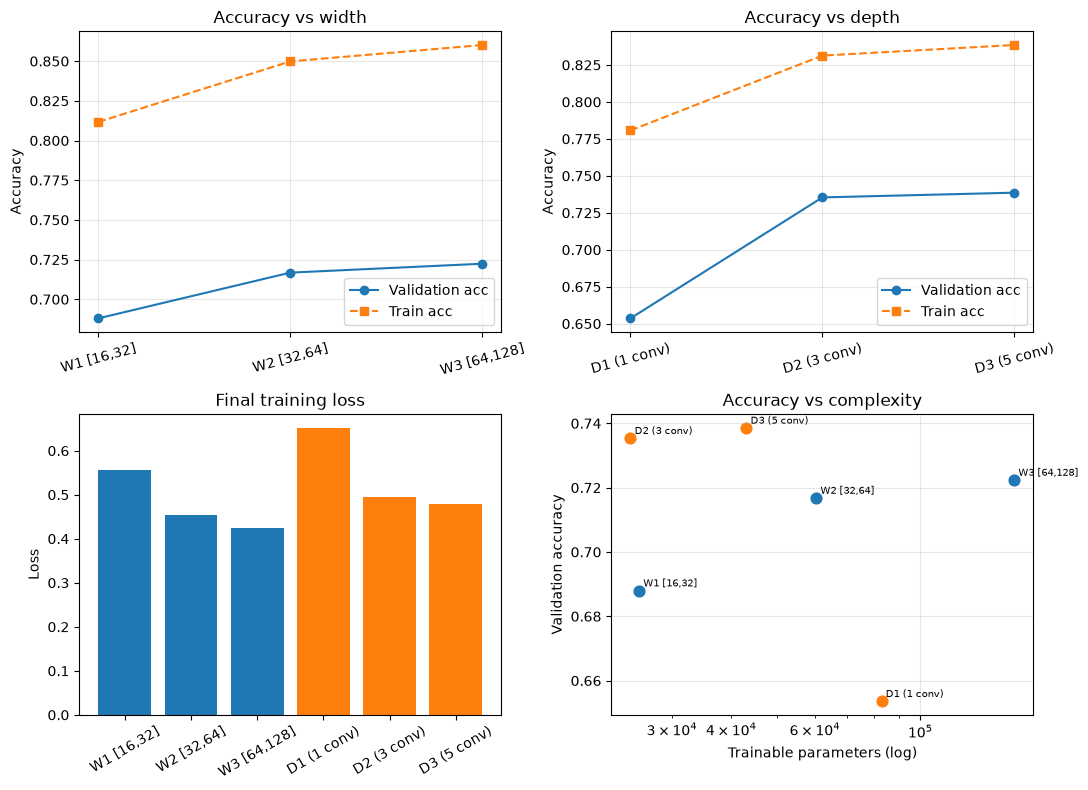

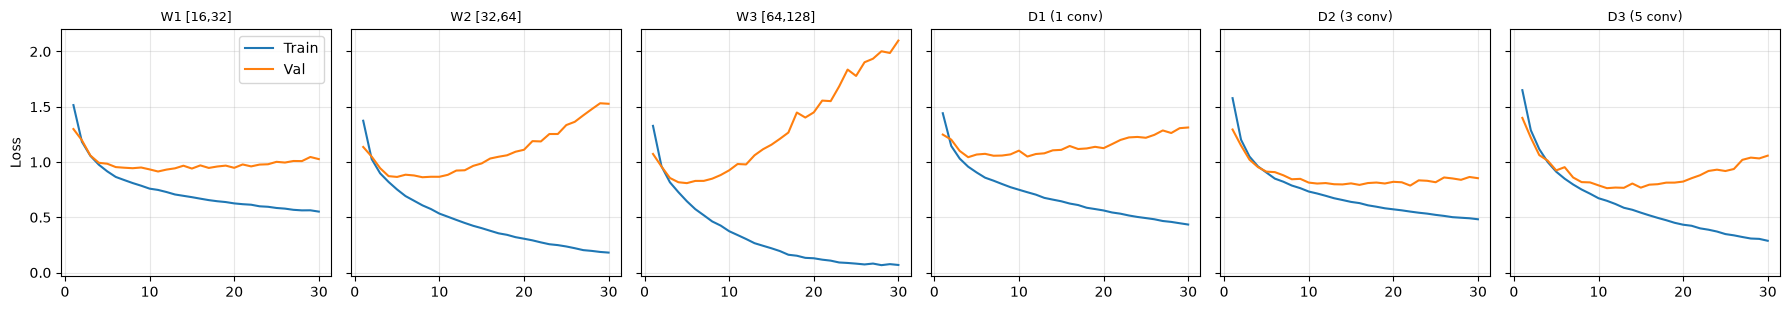

In [10]:
W, D = res[res.kind == "width"], res[res.kind == "depth"]
fig, ax = plt.subplots(2, 2, figsize=(11, 8))
for a, d, t in [(ax[0, 0], W, "Width"), (ax[0, 1], D, "Depth")]:
    a.plot(d["variant"], d["val_acc"], "o-", label="Validation acc")
    a.plot(d["variant"], d["train_acc"], "s--", label="Train acc")
    a.set(title=f"Accuracy vs {t.lower()}", ylabel="Accuracy"); a.legend(); a.grid(alpha=.3)
    a.tick_params(axis="x", rotation=15)
ax[1, 0].bar(res["variant"], res["train_loss"], color=["tab:blue"]*3 + ["tab:orange"]*3)
ax[1, 0].set(title="Final training loss", ylabel="Loss"); ax[1, 0].tick_params(axis="x", rotation=30)
for _, r in res.iterrows():
    ax[1, 1].scatter(r["params"], r["val_acc"], c="tab:blue" if r["kind"] == "width" else "tab:orange", s=60)
    ax[1, 1].annotate(r["variant"], (r["params"], r["val_acc"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax[1, 1].set(xscale="log", xlabel="Trainable parameters (log)", ylabel="Validation accuracy", title="Accuracy vs complexity")
ax[1, 1].grid(alpha=.3); plt.tight_layout(); plt.savefig("figures/ex4_summary.png", dpi=200); plt.show()

fig, ax = plt.subplots(1, 6, figsize=(18, 3.2), sharey=True)
for a, name in zip(ax, VARIANTS):
    h = hists[(name, SEEDS[0])]; e = range(1, EPOCHS + 1)
    a.plot(e, h["train_loss"], label="Train"); a.plot(e, h["val_loss"], label="Val"); a.set_title(name, fontsize=9); a.grid(alpha=.3)
ax[0].legend(); ax[0].set_ylabel("Loss"); plt.tight_layout(); plt.savefig("figures/ex4_loss_curves.png", dpi=200); plt.show()

### Notes for the report
- Relationship between parameters, accuracy and training loss; diminishing returns?
- Overfitting: train-val gap and where validation loss turns upward as capacity grows.
- Depth: very shallow nets underfit; deeper nets without normalisation/residuals may train slowly (vanishing gradients) - only claim what your results show.
- Note computational cost (`time_s`, parameters).